In [1]:
ROOT = '/home/jupyter-r.yazdi/myproject/dti3d/0pycodes/UnetMaxsig/BUSI_WHU/'
config = {
    "lr": 1e-4,
    "batch_size": 8,
    "epochs": 100,
    }

In [2]:
from time import perf_counter
import numpy as np
import cv2
import matplotlib.pyplot as plt

import os
from glob import glob
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
from torchvision import transforms
import torchvision.transforms.functional as TF
from torchvision.utils import make_grid
from PIL import Image

from torch.optim.lr_scheduler import StepLR
from torch.utils.data import DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2
from torchvision.models.segmentation import deeplabv3_resnet50, deeplabv3_resnet101

/home/jupyter-r.yazdi/.local/lib/python3.10/site-packages/albumentations/check_version.py:49: UserWarning: Error fetching version info <urlopen error [Errno 101] Network is unreachable>
  data = fetch_version_info()


In [3]:
#dataset
from torch.utils.data import Dataset
class mydataset(Dataset):
    def __init__(self,images_dir,masks_dir,transforms_img=None):
        self.images_dir=images_dir
        self.masks_dir=masks_dir
        self.transforms_img=transforms_img
        self.mask_names= glob(masks_dir + "*.bmp")

    def __len__(self):
        return len(self.mask_names)

    def __getitem__(self,index):
        mask_name=self.mask_names[index]
        mask=cv2.imread(mask_name,cv2.IMREAD_ANYDEPTH)
        mask = (mask - mask.min()) / (mask.max() - mask.min())#ejbari
        mask= (mask>0).astype(np.float32)
        mask = cv2.resize(mask, (256, 256), interpolation=cv2.INTER_AREA)

        imgn=mask_name.replace('/masks/','/images/').replace('_anno.bmp','.bmp')
              
        image=cv2.imread(imgn,cv2.IMREAD_ANYDEPTH)
        image = (image - image.min()) / (image.max() - image.min()).astype(np.float32)#ejbari
        image = cv2.resize(image, (256, 256), interpolation=cv2.INTER_AREA)

        if self.transforms_img is not None:
            transformed = self.transforms_img(image=image, mask=mask)
            image = transformed["image"]
            mask = transformed["mask"]

        return image, mask

In [4]:
#train dataset

images_dir= ROOT + 'dataset/train/images/'
masks_dir= ROOT + 'dataset/train/masks/'
batch_size=config['batch_size']
shuffle=True

train_transform = A.Compose([

    #A.RandomCrop(256,256,always_apply=True, p=1.0),
    #A.UnsharpMask (blur_limit=(3, 5), sigma_limit=0, alpha=(0.2, 0.5), threshold=10, always_apply=False, p=0.1),
    #A.RandomGamma (gamma_limit=(80, 150), always_apply=False, p=0.1),
    #A.RandomBrightnessContrast (brightness_limit=0.2, contrast_limit=0.5, brightness_by_max=True, always_apply=False, p=0.25),
    #A.PadIfNeeded (min_height=1048, min_width=790, border_mode=cv2.BORDER_CONSTANT, value=0,always_apply=True, p=1.0),

    A.Resize(256,256),
    ToTensorV2()])


train_ds=mydataset(images_dir=images_dir,masks_dir=masks_dir,transforms_img=train_transform)
print("number of loaded training images: ",train_ds.__len__())

train_dataset = DataLoader(train_ds,batch_size=batch_size,shuffle=shuffle)
print("loaded", len(train_dataset), "training batches.")

number of loaded training images:  555
loaded 70 training batches.


In [5]:
#val dataset

images_dir= ROOT + 'dataset/val/images/'
masks_dir= ROOT + 'dataset/val/masks/'
batch_size=config['batch_size']
shuffle=True

val_transform = A.Compose([

    #A.PadIfNeeded (min_height=790, min_width=790, border_mode=cv2.BORDER_CONSTANT, value=0,always_apply=True,  p=1.0),
    A.Resize(256,256),
    ToTensorV2()])

val_ds=mydataset(images_dir=images_dir,masks_dir=masks_dir,transforms_img=val_transform)
print("number of loaded val images: ",val_ds.__len__())

val_dataset = DataLoader(val_ds,batch_size=batch_size,shuffle=shuffle)
print("loaded", len(val_dataset), "validation batches.")

number of loaded val images:  186
loaded 24 validation batches.


data_batch.size= torch.Size([8, 1, 256, 256])
mask.size= torch.Size([8, 1, 256, 256])


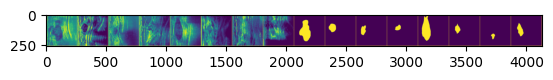

In [6]:

#data_batch, labels_batch = next(iter(train_dataset))
data_batch, mask= next(iter(train_dataset))

print('data_batch.size=',data_batch.size())
mask=mask.unsqueeze(1)
print('mask.size=',mask.size())
#crn=corner_response_map(data_batch)
tmp=torch.cat((data_batch, mask),0)
grid= make_grid(tmp,nrow=1,pad_value=1)
grid=grid.to('cpu')[1,...]
plt.imshow(grid.numpy().transpose((1, 0)))


In [7]:

# ============================================================
# MaxSigLayerNormalized (with proper C_in -> C_out projection)
# ============================================================
class MaxSigLayerNormalized(nn.Module):
    """
    Args:
        ch_in (int): input channels
        ch_out (int): output channels
        kernel_size (int): odd recommended
        stride (int): keep 1 to preserve H,W
        use_sigmoid_input (bool): apply sigmoid(x) before unfolding
    """
    def __init__(
        self,
        ch_in: int,
        ch_out: int,
        kernel_size: int,
        stride: int = 1,
        use_sigmoid_input: bool = True,
    ):
        super().__init__()
        assert kernel_size >= 1
        self.ch_in = ch_in
        self.ch_out = ch_out
        self.kernel_size = kernel_size
        self.stride = stride
        self.use_sigmoid_input = use_sigmoid_input

        self.padding = (kernel_size - 1) // 2
        self.kernel_area = kernel_size ** 2
        self.center_index = self.kernel_area // 2

        # learnable patch weights / bias (shared)
        self.weight = nn.Parameter(torch.rand(1, 1, self.kernel_area, 1, 1))
        self.bias   = nn.Parameter(torch.zeros(1, 1, self.kernel_area, 1, 1))

        # learnable scalars
        self.weight_center = nn.Parameter(torch.tensor(1.0))
        self.weight_median = nn.Parameter(torch.tensor(1.0))

        # proper projection
        self.proj = nn.Conv2d(ch_in, ch_out, kernel_size=1, bias=False)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        B, C_in, H, W = x.shape
        assert C_in == self.ch_in, f"Expected {self.ch_in} channels, got {C_in}"

        x_in = torch.sigmoid(x) if self.use_sigmoid_input else x

        x_unfold = F.unfold(
            x_in,
            kernel_size=self.kernel_size,
            padding=self.padding,
            stride=self.stride,
        )  # (B, C_in*K*K, L)

        _, CK2, L = x_unfold.shape
        assert CK2 == C_in * self.kernel_area

        out_h = (H + 2 * self.padding - self.kernel_size) // self.stride + 1
        out_w = (W + 2 * self.padding - self.kernel_size) // self.stride + 1

        x_unfold = x_unfold.view(B, C_in, self.kernel_area, out_h, out_w)

        w = torch.sigmoid(self.weight)  # (1,1,K*K,1,1)
        b = torch.sigmoid(self.bias)    # (1,1,K*K,1,1)

        D = torch.maximum(w, x_unfold) + b  # (B,C,K*K,out_h,out_w)

        mean_stat = torch.mean(D, dim=2)         # (B,C,out_h,out_w)
        median_stat, _ = torch.median(D, dim=2)  # (B,C,out_h,out_w)

        center_values = x_unfold[:, :, self.center_index, :, :]  # (B,C,out_h,out_w)

        out = (
            self.weight_center * center_values
            + self.weight_median * median_stat
            - mean_stat
        )  # (B,C_in,out_h,out_w)

        out = self.proj(out)  # (B,C_out,out_h,out_w)
        return out


In [8]:

class MaxSigGatedBlock(nn.Module):
    """
    Same gated-injection idea as your DownBlockWithMaxSig, factored out so it
    can be dropped anywhere in a feature pyramid:
 
        y = x + gamma * post(MaxSig(x))
 
    gamma starts at `gamma_init` (default 0.0) so a pretrained backbone's
    behavior is preserved at the start of fine-tuning.
    """
    def __init__(self, ch, kernel_size=3, gamma_init=0.0, use_sigmoid_input=True):
        super().__init__()
        self.maxsig = MaxSigLayerNormalized(
            ch_in=ch,
            ch_out=ch,
            kernel_size=kernel_size,
            stride=1,
            use_sigmoid_input=use_sigmoid_input,
        )
        self.post = nn.Sequential(
            nn.BatchNorm2d(ch),
            nn.LeakyReLU(0.1, inplace=True),
        )
        self.gamma = nn.Parameter(torch.tensor(float(gamma_init)))
 
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        m = self.post(self.maxsig(x))
        return x + self.gamma * m
 
 
class DeepLabV3MaxSig(nn.Module):
    """
    DeepLabV3 (ResNet50/101 backbone) with MaxSig gated blocks at up to two
    points:
 
      - "layer4"   : right after the backbone's last stage (2048 ch),
                     i.e. the ASPP input. Analog of injecting MaxSig at the
                     end of your deepest DownBlockWithMaxSig stage.
      - "aspp_out" : right after ASPP's 256-ch projection, before the final
                     3x3/1x1 conv + 16x upsample. This is the spot most
                     likely to help boundary sharpness, since plain
                     DeepLabV3 (no "+") has no low-level-feature decoder.
 
    Args:
        num_classes: 1 for binary segmentation (BCEWithLogitsLoss), else the
            number of semantic classes.
        backbone_name: "resnet50" or "resnet101".
        in_channels: input image channels. Your dataset is single-channel
            ultrasound, so this defaults to 1; the pretrained 3-channel stem
            conv is adapted by averaging its RGB filters (Krizhevsky-style).
        pretrained_backbone: load ImageNet-pretrained torchvision weights.
        maxsig_at: subset of {"layer4", "aspp_out"}.
        maxsig_kernel: kernel size passed to MaxSigLayerNormalized.
        gamma_init: initial gate value. 0.0 = identical to plain DeepLabV3 at
            the start of training (recommended, especially with a pretrained
            backbone).
        use_sigmoid_input: passed through to MaxSigLayerNormalized.
    """
    def __init__(
        self,
        num_classes: int = 1,
        backbone_name: str = "resnet50",
        in_channels: int = 1,
        pretrained_backbone: bool = True,
        maxsig_at=("layer4", "aspp_out"),
        maxsig_kernel: int = 3,
        gamma_init: float = 0.0,
        use_sigmoid_input: bool = True,
    ):
        super().__init__()
        assert backbone_name in ("resnet50", "resnet101")
        maxsig_at = set(maxsig_at)
        assert maxsig_at <= {"layer4", "aspp_out"}, \
            f"unknown maxsig_at entries: {maxsig_at - {'layer4', 'aspp_out'}}"
 
        builder = deeplabv3_resnet50 if backbone_name == "resnet50" else deeplabv3_resnet101
        base = builder(
            weights=None,
            weights_backbone="DEFAULT" if pretrained_backbone else None,
            num_classes=num_classes,
            aux_loss=False,
        )
 
        self.backbone = base.backbone      # IntermediateLayerGetter -> {'out': layer4 feats}
        self.classifier = base.classifier  # DeepLabHead: [ASPP, Conv3x3, BN, ReLU, Conv1x1]
 
        # --- adapt the stem conv for non-RGB input ---
        if in_channels != 3:
            old_conv = self.backbone.conv1
            new_conv = nn.Conv2d(
                in_channels, old_conv.out_channels,
                kernel_size=old_conv.kernel_size, stride=old_conv.stride,
                padding=old_conv.padding, bias=False,
            )
            if pretrained_backbone:
                with torch.no_grad():
                    w = old_conv.weight.mean(dim=1, keepdim=True)   # avg RGB filters
                    new_conv.weight.copy_(w.repeat(1, in_channels, 1, 1))
            self.backbone.conv1 = new_conv
 
        # --- MaxSig gated blocks ---
        self.msig_layer4 = (
            MaxSigGatedBlock(2048, maxsig_kernel, gamma_init, use_sigmoid_input)
            if "layer4" in maxsig_at else None
        )
        self.msig_aspp_out = (
            MaxSigGatedBlock(256, maxsig_kernel, gamma_init, use_sigmoid_input)
            if "aspp_out" in maxsig_at else None
        )
 
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        input_shape = x.shape[-2:]
 
        feats = self.backbone(x)["out"]           # (B, 2048, H/16, W/16)
        if self.msig_layer4 is not None:
            feats = self.msig_layer4(feats)
 
        aspp_out = self.classifier[0](feats)       # ASPP -> (B, 256, H/16, W/16)
        if self.msig_aspp_out is not None:
            aspp_out = self.msig_aspp_out(aspp_out)
 
        x = self.classifier[1](aspp_out)            # 3x3 conv
        x = self.classifier[2](x)                    # BatchNorm
        x = self.classifier[3](x)                    # ReLU
        x = self.classifier[4](x)                    # 1x1 conv -> num_classes
 
        x = F.interpolate(x, size=input_shape, mode="bilinear", align_corners=False)
        return x

In [9]:
# ============================================================
torch.manual_seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"

# ---- Binary semantic segmentation example ----
model = DeepLabV3MaxSig(
    num_classes=1,
    backbone_name="resnet50",
    in_channels=1,
    pretrained_backbone=False,
    maxsig_at=(),          # <-- no MaxSig blocks -> plain DeepLabV3
    maxsig_kernel=3,
    gamma_init=0.0,
    use_sigmoid_input=True,
).to(device)
total_params = sum(p.numel() for p in model.parameters())
print(f"Total parameters: {total_params:,}")

Total parameters: 39,627,457


In [10]:

data_batch,mask_name = next(iter(train_dataset))
print("data_batch.size=",data_batch.size())

criterion = nn.BCEWithLogitsLoss()

optimizer = optim.AdamW(model.parameters(),lr=1e-4)

scheduler = StepLR(optimizer, step_size=100, gamma=0.83)
scaler = torch.amp.GradScaler('cuda')

best_valid_dice=0
best_epoch=0
train_loss_plot=[]
val_loss_plot=[]
val_dice_plot=[]
last_lr=scheduler.get_last_lr()

for epoch in range(config['epochs']):

    if(last_lr != scheduler.get_last_lr()):
        print(80*'-')
        #net.load_state_dict(torch.load('f:/pred_img/best-model.pt'))
        print(f'The lr changed from {last_lr} to {scheduler.get_last_lr()}. thus previous best model loaded!')
        last_lr = scheduler.get_last_lr()

    print("\r\nepoch ",epoch+1," started!",' LR=', last_lr)

    t_start = perf_counter()

    #model training step
    running_loss = 0.0
    model.train()
    for inputs,mask in train_dataset:

        optimizer.zero_grad()
        with torch.autocast(device_type="cuda"):
            outputs = model(inputs.to(device))
            labels=mask.to(device).unsqueeze(1)
            loss = criterion(outputs, labels)

        running_loss += loss.item()
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

    ep_loss=running_loss / len(train_dataset)
    print("train_loss: " ,ep_loss)
    train_loss_plot.append(ep_loss)
    scheduler.step()

    #model evaluation step
    dice_score = 0
    val_loss = 0.0
    with torch.no_grad():
        model.eval()
        for inputs,mask in val_dataset:

            inputs=inputs.to(device)
            preds =model(inputs)
            labels=mask.to(device).unsqueeze(1)
            loss = criterion(preds, labels)
            val_loss += loss.item()

            pred_sig=torch.sigmoid(preds)

            preds=(pred_sig>0.5).float()
            intersection=(preds * labels).sum()
            union=(preds + labels).sum()
            dice_score += (2 * intersection / union)

    ep_loss=val_loss / len(val_dataset)
    print("val_loss: " ,ep_loss)
    val_loss_plot.append(ep_loss)
    epoch_dc= float(dice_score/len(val_dataset))
    val_dice_plot.append(epoch_dc)
    print(f"Validation_Dice Score = {epoch_dc:.12f}")
    if(best_valid_dice< epoch_dc):
        best_valid_dice=epoch_dc
        best_epoch=epoch
        torch.save(model.state_dict(), ROOT+'best-deeplab.pt')
        print('The best model saved...')
        #tmp=torch.cat((labels,preds),0)
        #grid= make_grid(tmp,nrow=6,pad_value=1)
        #torchvision.utils.save_image(grid, f"f:/pred_img/sim/all/{epoch+1}.tif")

    print('Best validation dice=',best_valid_dice, ' in epoch ', best_epoch+1)
    #print(net.m1.weight.detach().cpu().numpy())
    print(f"Epoch finished in {perf_counter()-t_start} seconds.\r\n")


data_batch.size= torch.Size([8, 1, 256, 256])

epoch  1  started!  LR= [0.0001]
train_loss:  0.34220478811434335
val_loss:  0.24005616890887418
Validation_Dice Score = 0.519887924194
The best model saved...
Best validation dice= 0.5198879241943359  in epoch  1
Epoch finished in 5.667695795185864 seconds.


epoch  2  started!  LR= [0.0001]
train_loss:  0.18706997207232884
val_loss:  0.1815433812638124
Validation_Dice Score = 0.636033117771
The best model saved...
Best validation dice= 0.6360331177711487  in epoch  2
Epoch finished in 6.264985593035817 seconds.


epoch  3  started!  LR= [0.0001]
train_loss:  0.14027298177991596
val_loss:  0.13834870606660843
Validation_Dice Score = 0.721344172955
The best model saved...
Best validation dice= 0.7213441729545593  in epoch  3
Epoch finished in 6.198323384160176 seconds.


epoch  4  started!  LR= [0.0001]
train_loss:  0.11318462586828641
val_loss:  0.11431369464844465
Validation_Dice Score = 0.759226739407
The best model saved...
Best valida

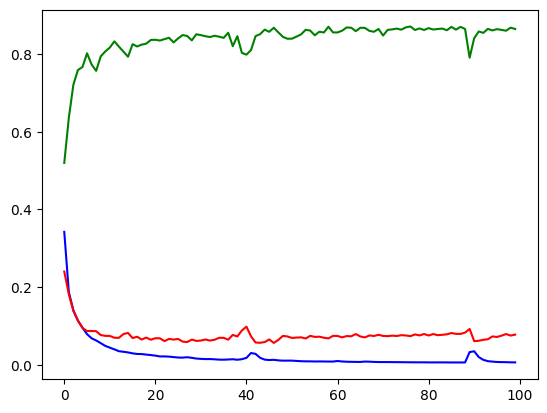

In [11]:
plt.plot(train_loss_plot, color='blue',label='train_loss')
plt.plot(val_loss_plot, color='red',label='val_loss')
plt.plot(val_dice_plot ,color='green',label='val_dice')
plt.show()

In [12]:
#test dataset

images_dir= ROOT + 'dataset/test/images/'
masks_dir= ROOT + 'dataset/test/masks/'
batch_size=config['batch_size']
shuffle=True

test_transform = A.Compose([

    #A.PadIfNeeded (min_height=790, min_width=790, border_mode=cv2.BORDER_CONSTANT, value=0,always_apply=True,  p=1.0),
    A.Resize(256,256),
    ToTensorV2()])

test_ds=mydataset(images_dir=images_dir,masks_dir=masks_dir,transforms_img=test_transform)
print("number of loaded test images: ",test_ds.__len__())

test_dataset = DataLoader(test_ds,batch_size=batch_size,shuffle=shuffle)
print("loaded", len(test_dataset), "test batches.")

number of loaded test images:  186
loaded 24 test batches.


In [13]:
torch.manual_seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"

# ---- Binary semantic segmentation example ----
model = DeepLabV3MaxSig(
    num_classes=1,
    backbone_name="resnet50",
    in_channels=1,
    pretrained_backbone=False,
    maxsig_at=(),          # <-- no MaxSig blocks -> plain DeepLabV3
    maxsig_kernel=3,
    gamma_init=0.0,
    use_sigmoid_input=True,
).to(device)
#model evaluation step
dice_score = 0
model.load_state_dict(torch.load('best-deeplab.pt'))
with torch.no_grad():
    model.eval()
    for inputs,mask in test_dataset:

        inputs=inputs.to(device)
        preds =model(inputs)
        labels=mask.to(device).unsqueeze(1)        
        pred_sig=torch.sigmoid(preds)
        preds=(pred_sig>0.5).float()
        intersection=(preds * labels).sum()
        union=(preds + labels).sum()
        dice_score += (2 * intersection / union)

epoch_dc= float(dice_score/len(test_dataset))

print(f"test Dice Score = {epoch_dc:.12f}")


test Dice Score = 0.859954237938
